
# Task 2: Python and SQL Integration

## ApexPlanet Data Analytics Internship

### Project: Superstore Sales Analysis

**Objective:** Integrate Python with an SQLite database using SQLAlchemy and pandas to perform sales analysis and create business visualizations.

### Tools Used
- Python
- SQLite
- SQLAlchemy
- Pandas
- Matplotlib

### Analysis Performed
- Total Sales and Profit Analysis
- Category-wise Sales Analysis
- Monthly Sales Trend
- Regional Sales Analysis
- Top 10 Customers by Sales
- Sales vs Profit Analysis
- Sales Distribution


In [1]:
# Import required libraries
import pandas as pd
import sqlite3
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
from pathlib import Path

# Define database path
DB_PATH = Path("../superstore.db")

# Create database connection
engine = create_engine(f"sqlite:///{DB_PATH.resolve().as_posix()}")

# Test database connection
print("Database connected successfully!")

Database connected successfully!


In [2]:
# Load Superstore data from SQLite database

query = """
SELECT *
FROM superstore
LIMIT 10;
"""

# Fetch data using pandas
data = pd.read_sql(query, engine)

# Display first 10 rows
data

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.551200
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.5,-5.487000
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.271700
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-39.544887
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.884000
5,6,US-2023-167199,2023-01-06,2023-01-10,Standard Class,ME-17320,Maria Etezadi,Home Office,United States,Henderson,...,42420,South,FUR-CH-10004063,Furniture,Chairs,Global Deluxe High-Back Manager's Chair,497.920,9,0.0,70.603612
6,7,US-2023-167199,2023-01-06,2023-01-10,Standard Class,ME-17320,Maria Etezadi,Home Office,United States,Henderson,...,42420,South,OFF-AR-10001662,Office Supplies,Art,Rogers Handheld Barrel Pencil Sharpener,5.480,2,0.0,1.479600
7,8,US-2023-106054,2023-01-06,2023-01-07,First Class,JO-15145,Jack O'Briant,Corporate,United States,Athens,...,30605,South,OFF-AR-10002399,Office Supplies,Art,"Dixon Prang Watercolor Pencils, 10-Color Set w...",12.780,3,0.0,5.239800
8,9,US-2023-167199,2023-01-06,2023-01-10,Standard Class,ME-17320,Maria Etezadi,Home Office,United States,Henderson,...,42420,South,OFF-BI-10004632,Office Supplies,Binders,Ibico Hi-Tech Manual Binding System,497.920,2,0.0,70.603612
9,10,US-2023-167199,2023-01-06,2023-01-10,Standard Class,ME-17320,Maria Etezadi,Home Office,United States,Henderson,...,42420,South,OFF-FA-10001883,Office Supplies,Fasteners,"Alliance Super-Size Bands, Assorted Sizes",31.120,4,0.0,0.311200


In [3]:
# Calculate total sales and total profit

query = """
SELECT
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit
FROM superstore;
"""

# Fetch results from SQL
data = pd.read_sql(query, engine)

# Display results
data

,total_sales,total_profit
0,1.422048e+06,163579.955112


In [4]:
# Category-wise Sales and Profit Analysis

query = """
SELECT
    Category,
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit
FROM superstore
GROUP BY Category
ORDER BY total_sales DESC;
"""

# Fetch data
category_data = pd.read_sql(query, engine)

# Display results
category_data

,Category,total_sales,total_profit
0,Office Supplies,500550.8440,82909.083300
1,Furniture,490876.3664,25465.919562
2,Technology,430620.4590,55204.952250


In [5]:
# Monthly Sales Analysis

query = """
SELECT
    strftime('%Y-%m', "Order Date") AS month,
    SUM(Sales) AS monthly_sales
FROM superstore
GROUP BY month
ORDER BY month;
"""

# Fetch monthly sales data
monthly_data = pd.read_sql(query, engine)

# Display results
monthly_data

,month,monthly_sales
0,2023-01,10200.5950
1,2023-02,3761.5920
2,2023-03,23236.6160
3,2023-04,18889.9910
4,2023-05,18708.4850
5,2023-06,21041.0206
6,2023-07,20484.7570
7,2023-08,21930.2125
8,2023-09,38518.8668
9,2023-10,22622.7630


In [6]:
# Regional Sales Analysis

query = """
SELECT
    Region,
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit
FROM superstore
GROUP BY Region
ORDER BY total_sales DESC;
"""

# Fetch regional sales data
region_data = pd.read_sql(query, engine)

# Display results
region_data

,Region,total_sales,total_profit
0,West,469976.5085,64459.257950
1,East,411105.9100,45896.505600
2,Central,312806.0954,23464.369050
3,South,228159.1555,29759.822512


In [7]:
# Top 10 Customers by Sales

query = """
SELECT
    "Customer Name",
    SUM(Sales) AS total_sales
FROM superstore
GROUP BY "Customer Name"
ORDER BY total_sales DESC
LIMIT 10;
"""

# Fetch top 10 customer data
customer_data = pd.read_sql(query, engine)

# Display results
customer_data

,Customer Name,total_sales
0,Ben Ferrer,5846.514
1,Clay Ludtke,5788.562
2,Seth Vernon,5769.491
3,Joe Elijah,5535.729
4,John Lee,5330.032
5,William Brown,5290.820
6,Laura Armstrong,5245.558
7,Paul Prost,5192.768
8,Brian Moss,5122.255
9,Dan Reichenbach,5109.448


In [8]:
# Top 10 Products by Sales

query = """
SELECT
    "Product Name",
    SUM(Sales) AS total_sales
FROM superstore
GROUP BY "Product Name"
ORDER BY total_sales DESC
LIMIT 10;
"""

# Fetch top 10 product data
product_data = pd.read_sql(query, engine)

# Display results
product_data

,Product Name,total_sales
0,SAFCO Arco Folding Chair,6574.296
1,Bretford Rectangular Conference Table Tops,6122.628
2,Global Deluxe High-Back Manager's Chair,5934.688
3,Tennsco Double-Tier Lockers,5609.256
4,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",5530.394
5,GBC DocuBind TL300 Electric Binding System,5477.120
6,"Hot File 7-Pocket, Floor Stand",5409.324
7,Adjustable Depth Letter/Legal Cart,5372.624
8,Tennsco 6- and 18-Compartment Lockers,5170.722
9,Chromcraft Round Conference Tables,5166.145


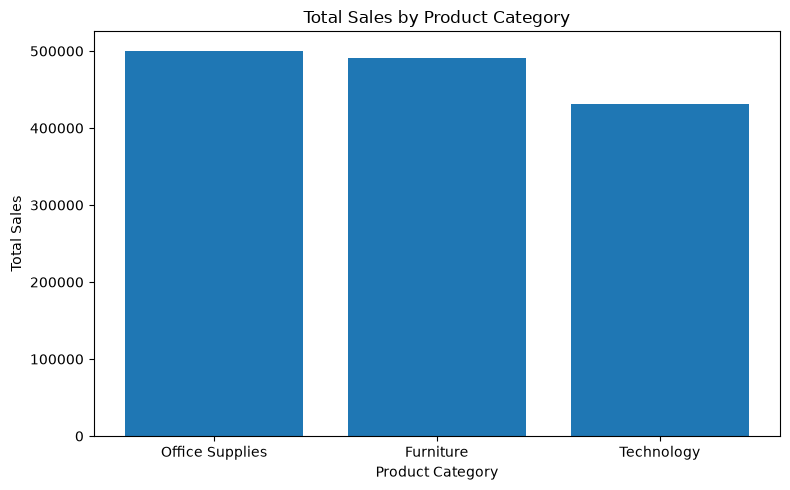

In [9]:
# Visualize Sales by Category

plt.figure(figsize=(8, 5))

plt.bar(
    category_data["Category"],
    category_data["total_sales"]
)

# Add chart title and labels
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

# Display chart
plt.tight_layout()
plt.show()

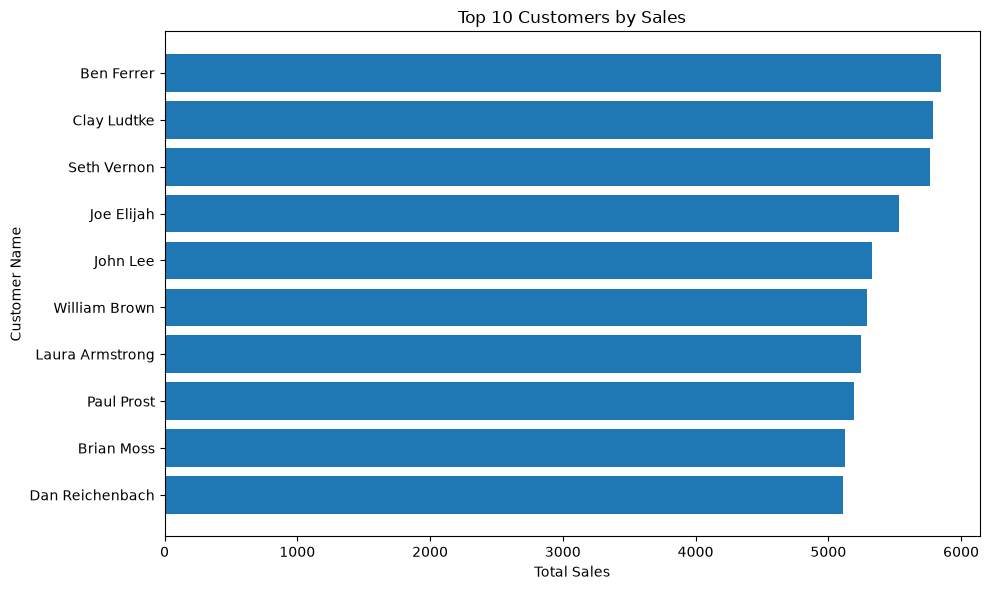

In [10]:
# Visualize Top 10 Customers by Sales

plt.figure(figsize=(10, 6))

plt.barh(
    customer_data["Customer Name"],
    customer_data["total_sales"]
)

# Show highest sales at the top
plt.gca().invert_yaxis()

# Add chart title and labels
plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")

# Display chart
plt.tight_layout()
plt.show()

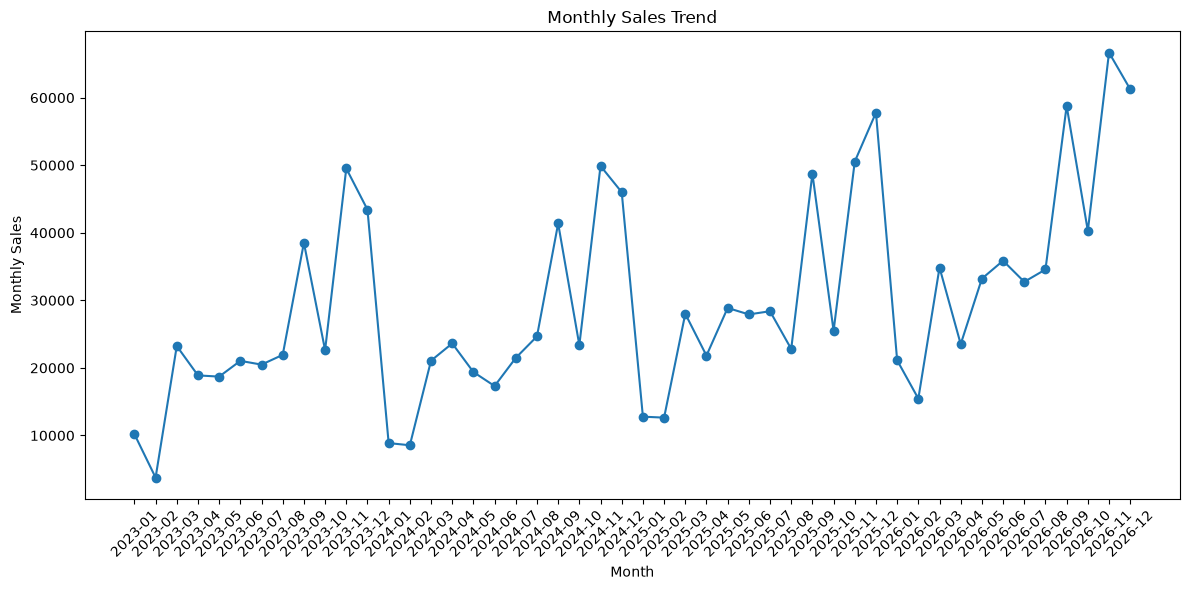

In [11]:
# Visualize Monthly Sales Trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_data["month"],
    monthly_data["monthly_sales"],
    marker="o"
)

# Add chart title and labels
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Monthly Sales")

# Rotate x-axis labels
plt.xticks(rotation=45)

# Display chart
plt.tight_layout()
plt.show()

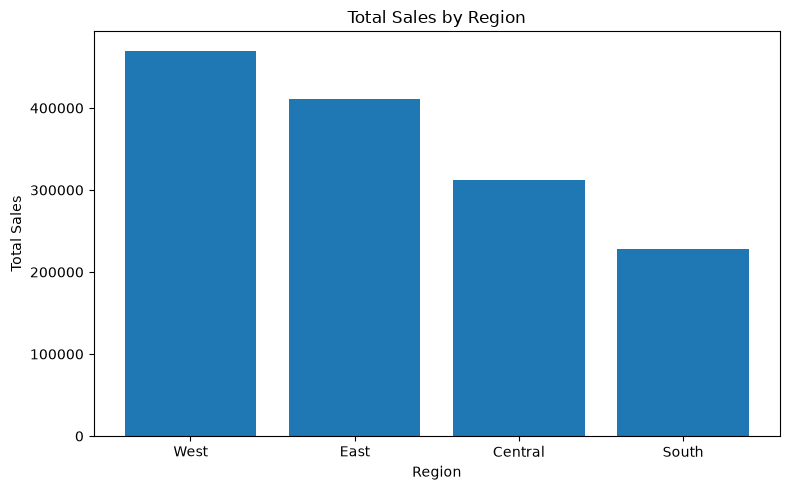

In [12]:
# Visualize Regional Sales

plt.figure(figsize=(8, 5))

plt.bar(
    region_data["Region"],
    region_data["total_sales"]
)

# Add chart title and labels
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

# Display chart
plt.tight_layout()
plt.show()

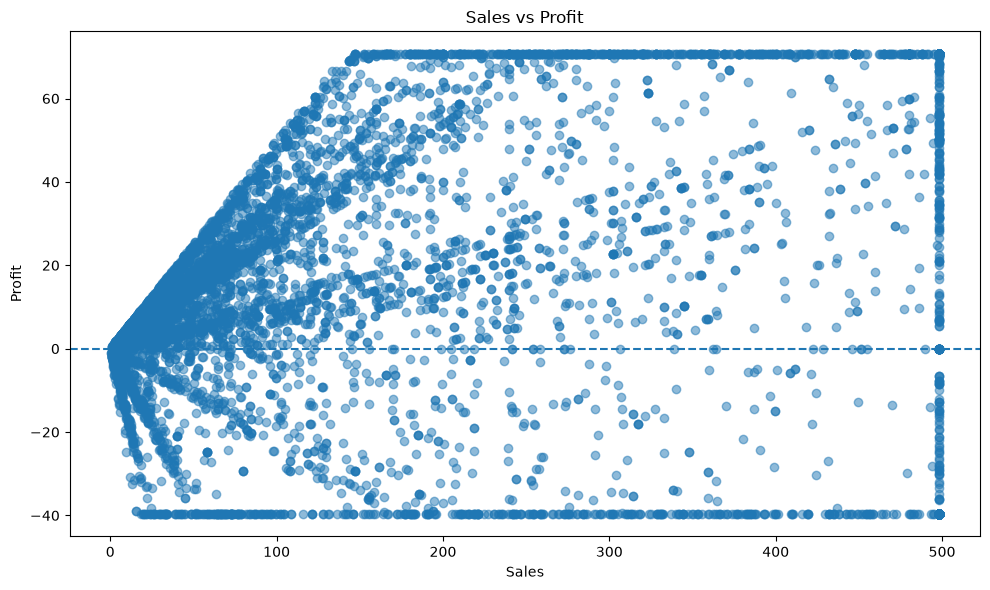

In [13]:
# Visualize Sales vs Profit

query = """
SELECT
    Sales,
    Profit
FROM superstore;
"""

# Fetch data from SQL
sales_profit_data = pd.read_sql(query, engine)

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    sales_profit_data["Sales"],
    sales_profit_data["Profit"],
    alpha=0.5
)

# Add zero-profit reference line
plt.axhline(y=0, linestyle="--")

# Add chart title and labels
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

# Display chart
plt.tight_layout()
plt.show()

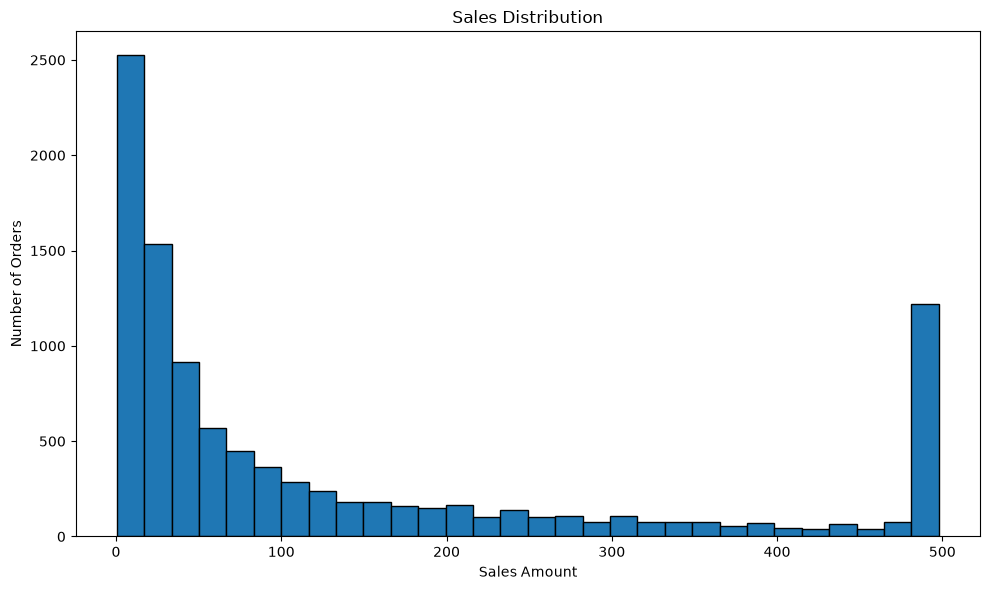

In [14]:
# Visualize Sales Distribution

query = """
SELECT
    Sales
FROM superstore;
"""

# Fetch data from SQL
sales_data = pd.read_sql(query, engine)

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    sales_data["Sales"],
    bins=30,
    edgecolor="black"
)

# Add chart title and labels
plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Orders")

# Display chart
plt.tight_layout()
plt.show()